In [2]:
import zipfile
from keras.utils import image_dataset_from_directory
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

from keras.callbacks import EarlyStopping
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten
from keras.utils import to_categorical

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

zipfile.ZipFile("archive.zip").extractall("data")

train_data = image_dataset_from_directory("data/train", image_size=(48,48), color_mode="grayscale")

test_data = image_dataset_from_directory("data/test", image_size=(48,48), color_mode="grayscale")

Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.


In [ ]:
# Class names
train_data.class_names

In [ ]:
# Number of classes
len(train_data.class_names)

In [ ]:
X_train, y_train = next(iter(train_data))

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

plt.imshow(X_train[0], cmap="binary")
plt.xticks([])
plt.yticks([])
plt.show()

In [ ]:
X_train.shape

TensorShape([32, 48, 48, 1])

In [ ]:
y_train.shape

TensorShape([32])

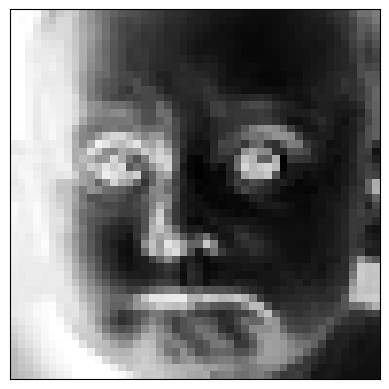

In [ ]:
plt.imshow(X_train[0, :, :, 0]/255, cmap="binary")
plt.xticks([])
plt.yticks([])
plt.show()

In [ ]:
from keras.models import Sequential
from keras.layers import Input, Dense, Flatten, Rescaling

model = Sequential([
    Input(shape=(48, 48, 1)),
    Rescaling(1./255),
    Flatten(),
    Dense(100, activation='relu'),
    Dense(100, activation='relu'),
    Dense(100, activation='relu'),
    Dense(7, activation='softmax')])

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=30,
    callbacks=[early_stop])

Epoch 1/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.2751 - loss: 1.7793 - val_accuracy: 0.3280 - val_loss: 1.6948
Epoch 2/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3252 - loss: 1.7008 - val_accuracy: 0.3238 - val_loss: 1.6963
Epoch 3/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3456 - loss: 1.6616 - val_accuracy: 0.3548 - val_loss: 1.6542
Epoch 4/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.3462 - loss: 1.6537 - val_accuracy: 0.3520 - val_loss: 1.6427
Epoch 5/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3584 - loss: 1.6354 - val_accuracy: 0.3242 - val_loss: 1.6900
Epoch 6/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.3627 - loss: 1.6302 - val_accuracy: 0.3616 - val_loss: 1.6288
Epoch 7/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3610 - loss: 1.6228 - val_accuracy: 0.3546 - val_loss: 1.6439
Epoch 8/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3668 - loss: 1.6136 - val_accuracy: 0

In [ ]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [ ]:
history = model.fit(train_data,validation_data=val_data,epochs=10)

In [ ]:
model2 = Sequential([
    Input(shape=(48, 48, 1)),
    Rescaling(1./255),
    Flatten(),
    Dense(200, activation='relu'),
    Dense(1000, activation='relu'),
    Dense(1000, activation='relu'),
    Dense(200, activation='relu'),
    Dense(1000, activation='relu'),
    Dense(1000, activation='relu'),
    Dense(7, activation='softmax')])

model2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

history2 = model2.fit(train_data,validation_data=val_data,epochs=30,callbacks=[early_stop])

In [ ]:
loss1, acc1 = model.evaluate(X_test, y_test)
loss2, acc2 = model2.evaluate(X_test, y_test)

print("Model 1 Accuracy:", acc1)
print("Model 2 Accuracy:", acc2)

In [ ]:
y_pred = np.argmax(best_model.predict(X_test), axis=1)

print(classification_report(y_test,y_pred,target_names=train_data.class_names,zero_division=0))

In [ ]:
best_model.save("emotion_model.keras")

In [ ]:
train_data, val_data = image_dataset_from_directory("data/train",image_size=(48, 48),color_mode="grayscale",validation_split=0.2,subset="both",seed=42)

Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Using 5741 files for validation.


In [ ]:
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model 1 Accuracy")
plt.legend()
plt.show()

In [ ]:
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model 1 Loss")
plt.legend()
plt.show()

In [ ]:
history = model.fit(train_data,validation_data=val_data,epochs=100)

Epoch 1/100
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.2743 - loss: 1.7821 - val_accuracy: 0.2864 - val_loss: 1.7991
Epoch 2/100
718/718 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.3260 - loss: 1.7007 - val_accuracy: 0.3318 - val_loss: 1.6891
Epoch 3/100
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.3447 - loss: 1.6653 - val_accuracy: 0.3473 - val_loss: 1.6638
Epoch 4/100
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3548 - loss: 1.6434 - val_accuracy: 0.3329 - val_loss: 1.6703
Epoch 5/100
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.3593 - loss: 1.6294 - val_accuracy: 0.3583 - val_loss: 1.6368
Epoch 6/100
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.3677 - loss: 1.6165 - val_accuracy: 0.3599 - val_loss: 1.6233
Epoch 7/100
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3713 - loss: 1.6053 - val_accuracy: 0.3672 - val_loss: 1.6137
Epoch 8/100
718/718 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.3735 - loss: 1.5927 - val_ac

In [ ]:
model.evaluate(test_data)

In [ ]:
model.evaluate(train_data)

718/718 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4894 - loss: 1.3518


[1.351836919784546, 0.4894200563430786]

In [ ]:
model.evaluate(val_data)

180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3623 - loss: 1.9376


[1.9376194477081299, 0.3623062074184418]

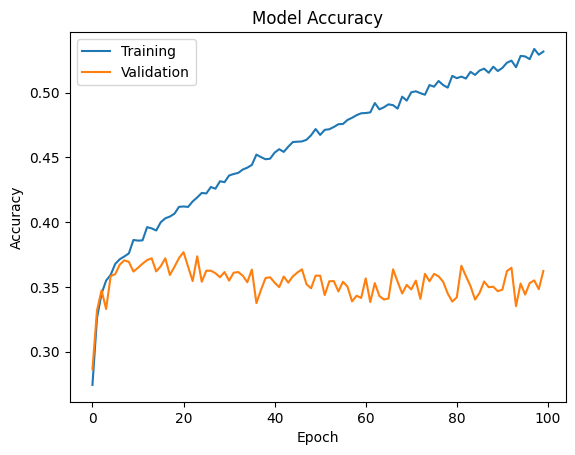

In [ ]:
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Model Accuracy')
plt.legend()
plt.show()

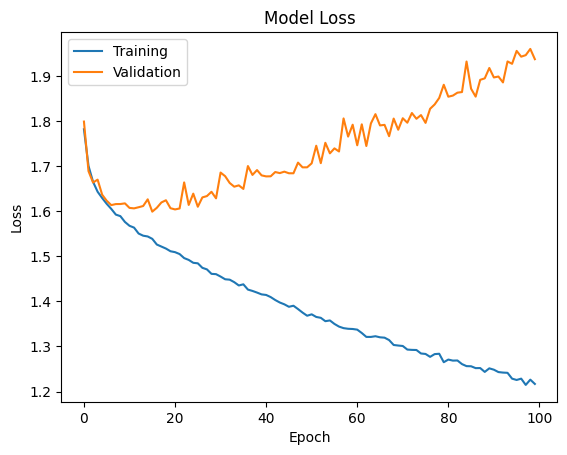

In [ ]:
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Model Loss')
plt.legend()
plt.show()

In [ ]:
model.evaluate(test_data)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3651 - loss: 1.9606


[1.9606068134307861, 0.3651435077190399]

In [ ]:
from keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_7 (Rescaling)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 100)            │       230,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 7)              │           707 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 251,407 (982.06 KB)

 Trainable params: 251,407 (982.06 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
test_data = image_dataset_from_directory("data/test",image_size=(48,48),color_mode="grayscale",shuffle=False)

Found 7178 files belonging to 7 classes.


Epoch 1/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.2734 - loss: 1.7842 - val_accuracy: 0.3200 - val_loss: 1.7086
Epoch 2/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.3238 - loss: 1.7055 - val_accuracy: 0.3350 - val_loss: 1.6771
Epoch 3/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.3406 - loss: 1.6731 - val_accuracy: 0.3264 - val_loss: 1.6889
Epoch 4/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3512 - loss: 1.6521 - val_accuracy: 0.3553 - val_loss: 1.6482
Epoch 5/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.3512 - loss: 1.6457 - val_accuracy: 0.3541 - val_loss: 1.6587
Epoch 6/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3592 - loss: 1.6379 - val_accuracy: 0.3620 - val_loss: 1.6390
Epoch 7/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.3583 - loss: 1.6331 - val_accuracy: 0.3585 - val_loss: 1.6373
Epoch 8/30
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3611 - loss: 1.6277 - val_accuracy: 0.

[1.6167917251586914, 0.37684592604637146]

In [ ]:
y_pred = model.predict(test_data)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [ ]:
import numpy as np

y_pred = np.argmax(y_pred, axis=1)

In [ ]:
y_pred[:10]

array([3, 3, 3, 5, 0, 6, 4, 2, 5, 3])

In [ ]:
np.array(test_data.class_names)[y_pred[:10]]

array(['happy', 'happy', 'happy', 'sad', 'angry', 'surprise', 'neutral',
       'fear', 'sad', 'happy'], dtype='<U8')

In [ ]:
y_true = pd.Series(test_data.file_paths).str.split(r"[/\\]", regex=True).str[-2]

In [ ]:
y_pred_names = np.array(test_data.class_names)[y_pred]

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred_names, zero_division=0))

              precision    recall  f1-score   support

       angry       0.25      0.20      0.22       958
     disgust       0.10      0.04      0.05       111
        fear       0.26      0.19      0.22      1024
       happy       0.46      0.61      0.53      1774
     neutral       0.31      0.37      0.34      1233
         sad       0.29      0.21      0.24      1247
    surprise       0.47      0.50      0.49       831

    accuracy                           0.37      7178
   macro avg       0.31      0.30      0.30      7178
weighted avg       0.34      0.37      0.35      7178



In [ ]:
model.evaluate(test_data)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3651 - loss: 1.9606


[1.960606575012207, 0.3651435077190399]

In [ ]:
y_pred = np.argmax(model.predict(test_data), axis=1)

y_true = pd.Series(test_data.file_paths).str.split(r"[/\\]", regex=True).str[-2]

print(classification_report(
    y_true,
    np.array(test_data.class_names)[y_pred],
    zero_division=0
))

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
              precision    recall  f1-score   support

       angry       0.25      0.20      0.22       958
     disgust       0.10      0.04      0.05       111
        fear       0.26      0.19      0.22      1024
       happy       0.46      0.61      0.53      1774
     neutral       0.31      0.37      0.34      1233
         sad       0.29      0.21      0.24      1247
    surprise       0.47      0.50      0.49       831

    accuracy                           0.37      7178
   macro avg       0.31      0.30      0.30      7178
weighted avg       0.34      0.37      0.35      7178



In [ ]:
test_data = image_dataset_from_directory("data/test",image_size=(48, 48),color_mode="grayscale",batch_size=7178,shuffle=False)

X_test, y_test = next(iter(test_data))

y_pred = np.argmax(model.predict(X_test), axis=1)

print(classification_report(y_test, y_pred, zero_division=0))

Found 7178 files belonging to 7 classes.
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

           0       0.25      0.20      0.22       958
           1       0.10      0.04      0.05       111
           2       0.26      0.19      0.22      1024
           3       0.46      0.61      0.53      1774
           4       0.31      0.37      0.34      1233
           5       0.29      0.21      0.24      1247
           6       0.47      0.50      0.49       831

    accuracy                           0.37      7178
   macro avg       0.31      0.30      0.30      7178
weighted avg       0.34      0.37      0.35      7178



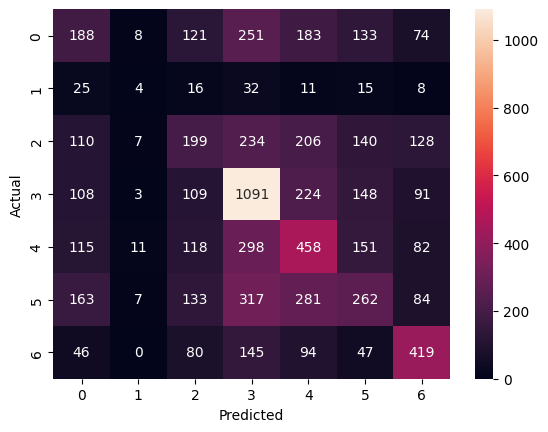

In [ ]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

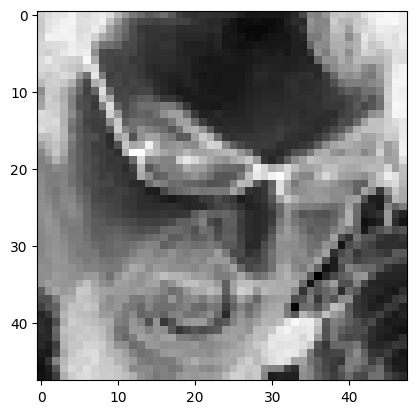

Actual: angry
Predicted: happy


In [ ]:
wrong = np.where(y_test.numpy() != y_pred)[0][0]

plt.imshow(X_test[wrong, :, :, 0], cmap='binary')
plt.show()

print("Actual:", test_data.class_names[int(y_test[wrong])])
print("Predicted:", test_data.class_names[y_pred[wrong]])

In [ ]:
model2 = Sequential([
    Input(shape=(48, 48, 1)),
    Rescaling(1./255),
    Flatten(),
    Dense(200, activation='relu'),
    Dense(1000, activation='relu'),
    Dense(1000, activation='relu'),
    Dense(200, activation='relu'),
    Dense(1000, activation='relu'),
    Dense(1000, activation='relu'),
    Dense(7, activation='softmax')
])

model2.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_9 (Rescaling)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 200)            │       461,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 1000)           │       201,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 1000)           │     1,001,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 200)            │       200,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 1000)           │       201,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 1000)           │     1,001,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 7)              │         7,007 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,072,207 (11.72 MB)

 Trainable params: 3,072,207 (11.72 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

In [ ]:
history2 = model2.fit(
    train_data,
    validation_data=val_data,
    epochs=10)

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 23s 30ms/step - accuracy: 0.2528 - loss: 1.8050 - val_accuracy: 0.2658 - val_loss: 1.7813
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 21s 29ms/step - accuracy: 0.2680 - loss: 1.7713 - val_accuracy: 0.2803 - val_loss: 1.7439
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 32s 45ms/step - accuracy: 0.2870 - loss: 1.7510 - val_accuracy: 0.2857 - val_loss: 1.7734
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 35s 36ms/step - accuracy: 0.2854 - loss: 1.7506 - val_accuracy: 0.3060 - val_loss: 1.7303
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 29s 40ms/step - accuracy: 0.2580 - loss: 1.8003 - val_accuracy: 0.2442 - val_loss: 1.8100
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 26s 36ms/step - accuracy: 0.2531 - loss: 1.8113 - val_accuracy: 0.2442 - val_loss: 1.8104
Epoch 7/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 50s 49ms/step - accuracy: 0.2531 - loss: 1.8112 - val_accuracy: 0.2442 - val_loss: 1.8103
Epoch 8/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step - accuracy: 0.2533 - loss: 1.8116 - 

In [ ]:
model2.evaluate(test_data)